<a href="https://colab.research.google.com/github/JOICEMARTINS84/sistema-solar-3d/blob/main/Experimento_001_M67.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install astropy photutils==3.1.1

Filename: /root/.astropy/cache/download/url/ca45ecc0ca77a21955d0e93af899c1da/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     104   (1059, 1059)   int16   


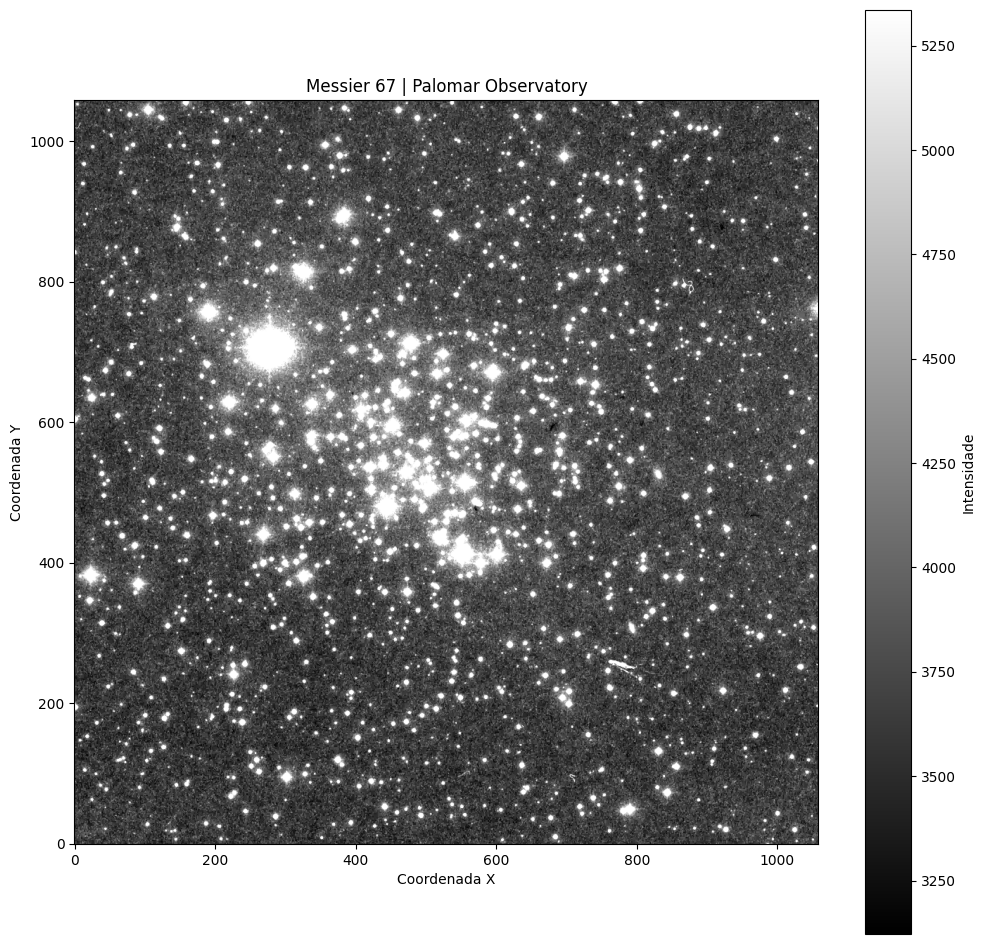

Dimensões: (1059, 1059)
Quantidade de pixels: 1121481


In [3]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.visualization import ZScaleInterval
from photutils.datasets import get_path

arquivo = get_path(
    'M6707HH.fits',
    location='remote'
)

with fits.open(arquivo) as hdul:
    hdul.info()
    imagem = hdul[0].data.astype(float)
    cabecalho = hdul[0].header.copy()

vmin, vmax = ZScaleInterval().get_limits(imagem)

plt.figure(figsize=(12, 12))
plt.imshow(imagem, cmap='gray',
           origin='lower', vmin=vmin, vmax=vmax)

plt.title('Messier 67 | Palomar Observatory')
plt.xlabel('Coordenada X')
plt.ylabel('Coordenada Y')
plt.colorbar(label='Intensidade')
plt.show()

print('Dimensões:', imagem.shape)
print('Quantidade de pixels:', imagem.size)

Média: 3770.49
Mediana: 3744.00
Desvio padrão: 237.21
Fontes detectadas: 1888


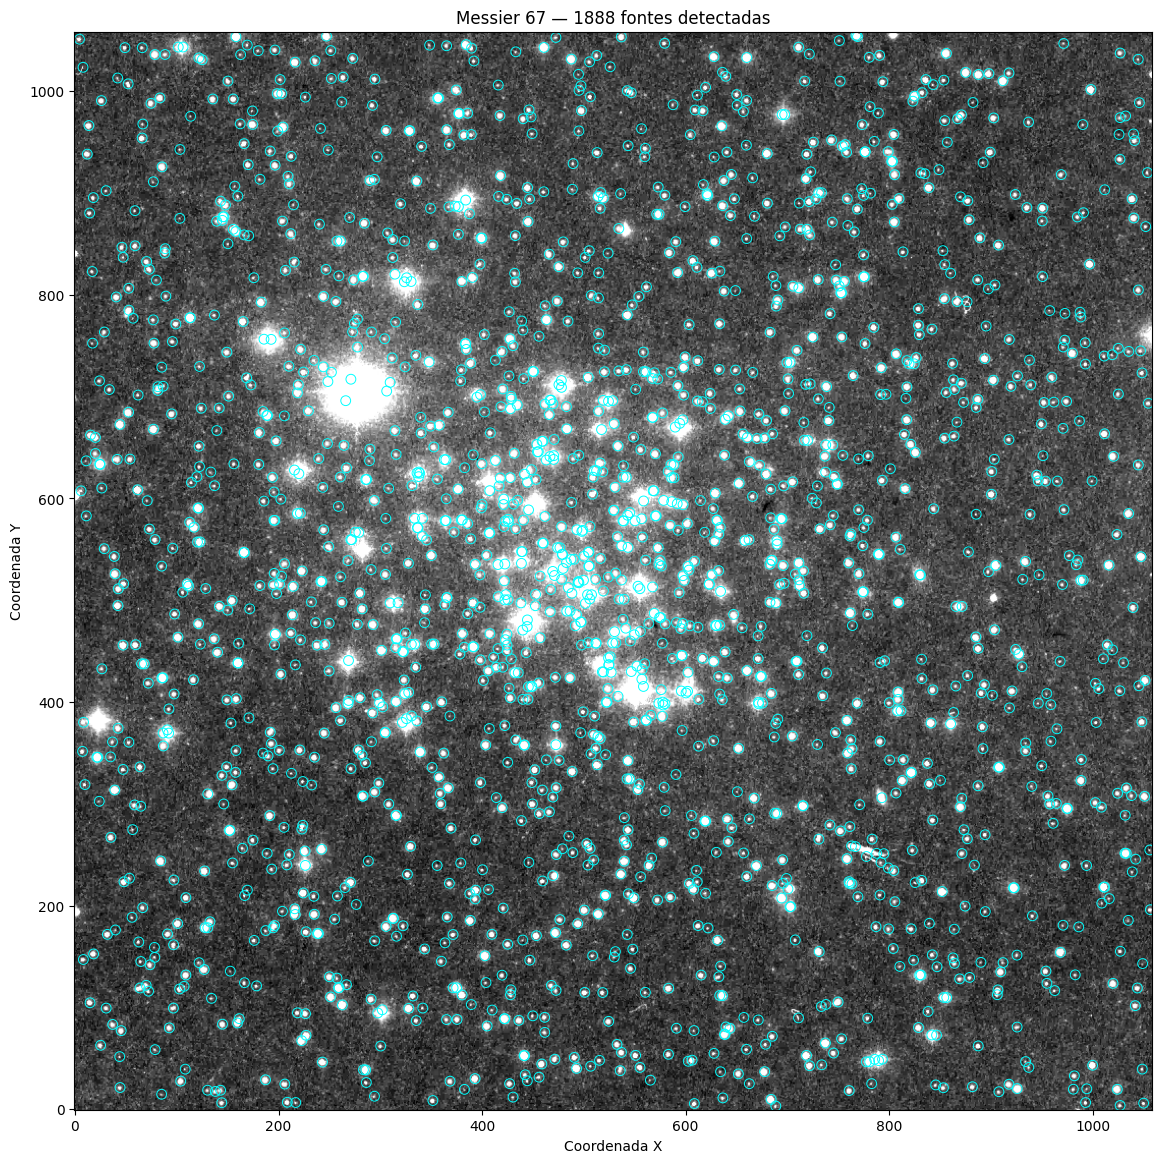

In [4]:
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder

# Estatística do fundo da imagem
media, mediana, desvio = sigma_clipped_stats(
    imagem, sigma=3.0
)

# Parâmetros iniciais de detecção
detector = DAOStarFinder(
    fwhm=3.0,
    threshold=5 * desvio,
    min_separation=3.0,
    exclude_border=True
)

fontes = detector(imagem - mediana)
total = len(fontes) if fontes is not None else 0

print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio padrão: {desvio:.2f}")
print(f"Fontes detectadas: {total}")

# Visualização das detecções
plt.figure(figsize=(14, 14))

plt.imshow(
    imagem,
    cmap='gray',
    origin='lower',
    vmin=vmin,
    vmax=vmax
)

if total > 0:
    plt.scatter(
        fontes['x_centroid'],
        fontes['y_centroid'],
        s=50,
        facecolors='none',
        edgecolors='cyan',
        linewidths=0.7
    )

plt.title(f"Messier 67 — {total} fontes detectadas")
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")

plt.savefig("M67_deteccao.png", dpi=300)
plt.show()

,Sigma,Limiar,Fontes detectadas
0,3,711.636457,2605
1,4,948.848609,2050
2,5,1186.060761,1888
3,6,1423.272914,1803
4,7,1660.485066,1729
5,8,1897.697218,1666
6,9,2134.909370,1605


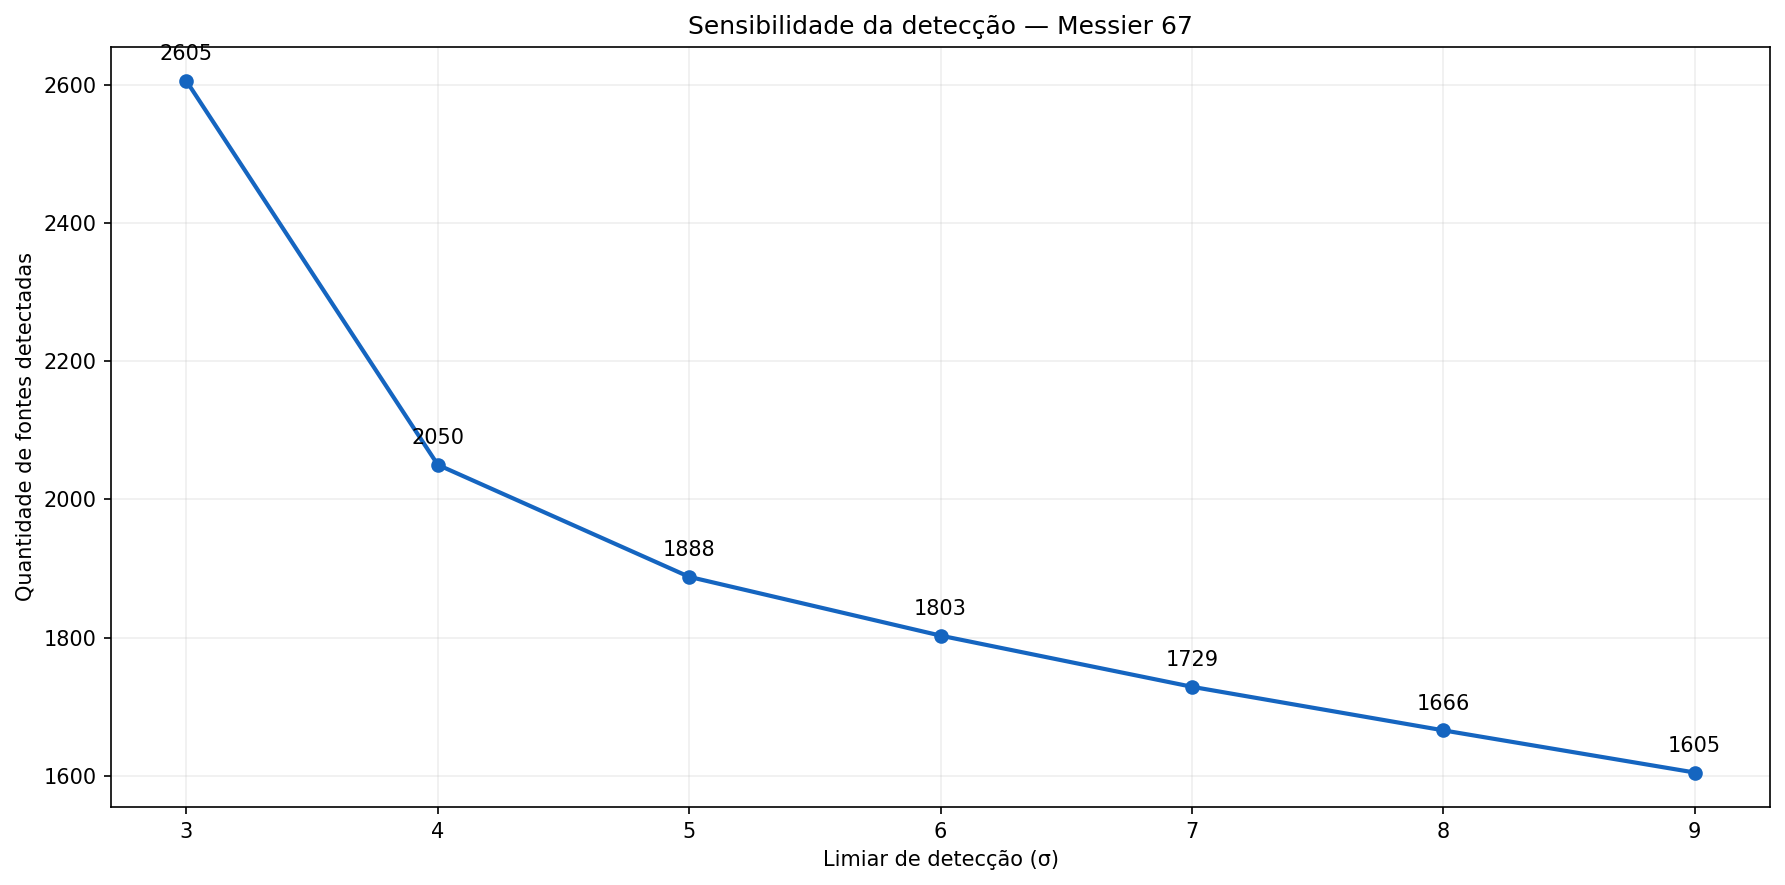

In [5]:
import pandas as pd

resultados = []

for k in range(3, 10):

    detector = DAOStarFinder(
        fwhm=3.0,
        threshold=k * desvio,
        min_separation=3.0,
        exclude_border=True
    )

    deteccoes = detector(imagem - mediana)
    quantidade = len(deteccoes) if deteccoes is not None else 0

    resultados.append({
        'Sigma': k,
        'Limiar': k * desvio,
        'Fontes detectadas': quantidade
    })

tabela = pd.DataFrame(resultados)
display(tabela)

# Gráfico científico
plt.figure(figsize=(12, 6), dpi=150)

plt.plot(
    tabela['Sigma'],
    tabela['Fontes detectadas'],
    marker='o',
    color='#1565C0',
    linewidth=2
)

for x, y in zip(tabela['Sigma'], tabela['Fontes detectadas']):
    plt.annotate(str(y), (x, y),
                 xytext=(0, 10),
                 textcoords='offset points',
                 ha='center')

plt.title('Sensibilidade da detecção — Messier 67')
plt.xlabel('Limiar de detecção (σ)')
plt.ylabel('Quantidade de fontes detectadas')
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig('M67_sensibilidade.png', dpi=300)
plt.show()

tabela.to_csv('M67_sensibilidade.csv', index=False)

,Sigma,Positivas,Negativas,Contaminacao_estimada (%)
0,3,2605,214,8.21
1,4,2050,133,6.49
2,5,1888,117,6.20
3,6,1803,104,5.77
4,7,1729,84,4.86
5,8,1666,62,3.72
6,9,1605,42,2.62


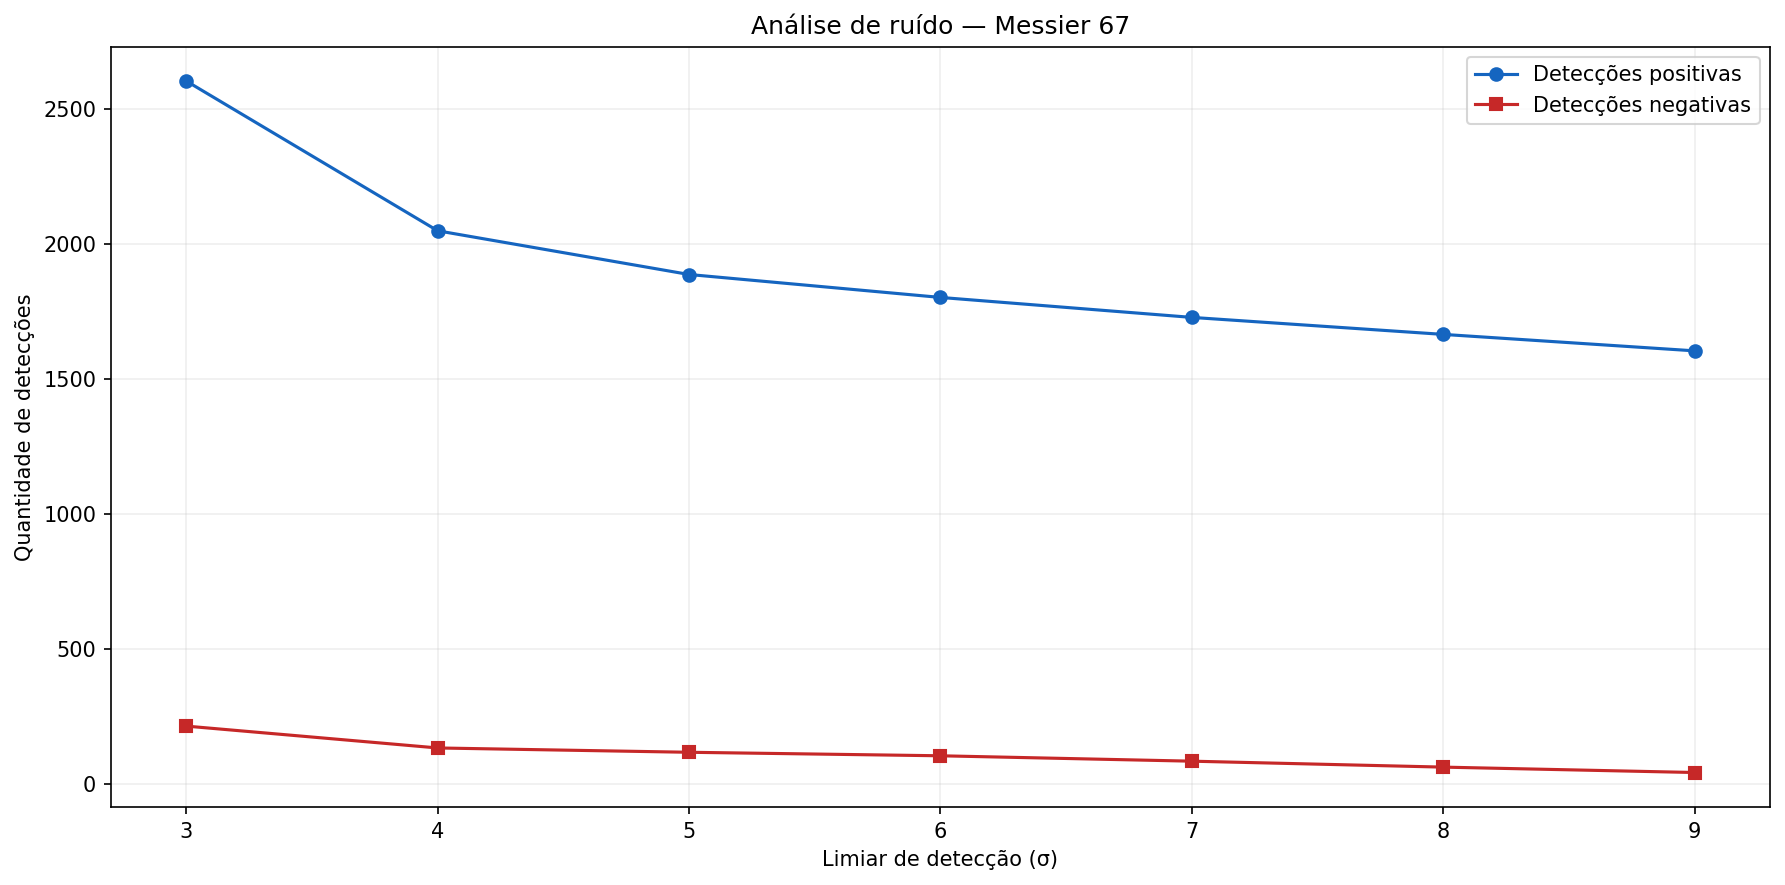

In [6]:
imagem_positiva = imagem - mediana
imagem_negativa = -imagem_positiva

resultados = []

for k in range(3, 10):

    detector = DAOStarFinder(
        fwhm=3.0,
        threshold=k * desvio,
        min_separation=3.0,
        exclude_border=True
    )

    positivas = detector(imagem_positiva)
    negativas = detector(imagem_negativa)

    np_ = len(positivas) if positivas is not None else 0
    nn_ = len(negativas) if negativas is not None else 0

    resultados.append({
        'Sigma': k,
        'Positivas': np_,
        'Negativas': nn_,
        'Contaminacao_estimada (%)':
            100 * nn_ / np_ if np_ > 0 else np.nan
    })

controle = pd.DataFrame(resultados)

display(controle.round(2))

plt.figure(figsize=(12, 6), dpi=150)

plt.plot(
    controle['Sigma'], controle['Positivas'],
    'o-', color='#1565C0',
    label='Detecções positivas'
)

plt.plot(
    controle['Sigma'], controle['Negativas'],
    's-', color='#C62828',
    label='Detecções negativas'
)

plt.title('Análise de ruído — Messier 67')
plt.xlabel('Limiar de detecção (σ)')
plt.ylabel('Quantidade de detecções')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('M67_analise_ruido.png', dpi=300)
plt.show()

controle.to_csv('M67_analise_ruido.csv', index=False)

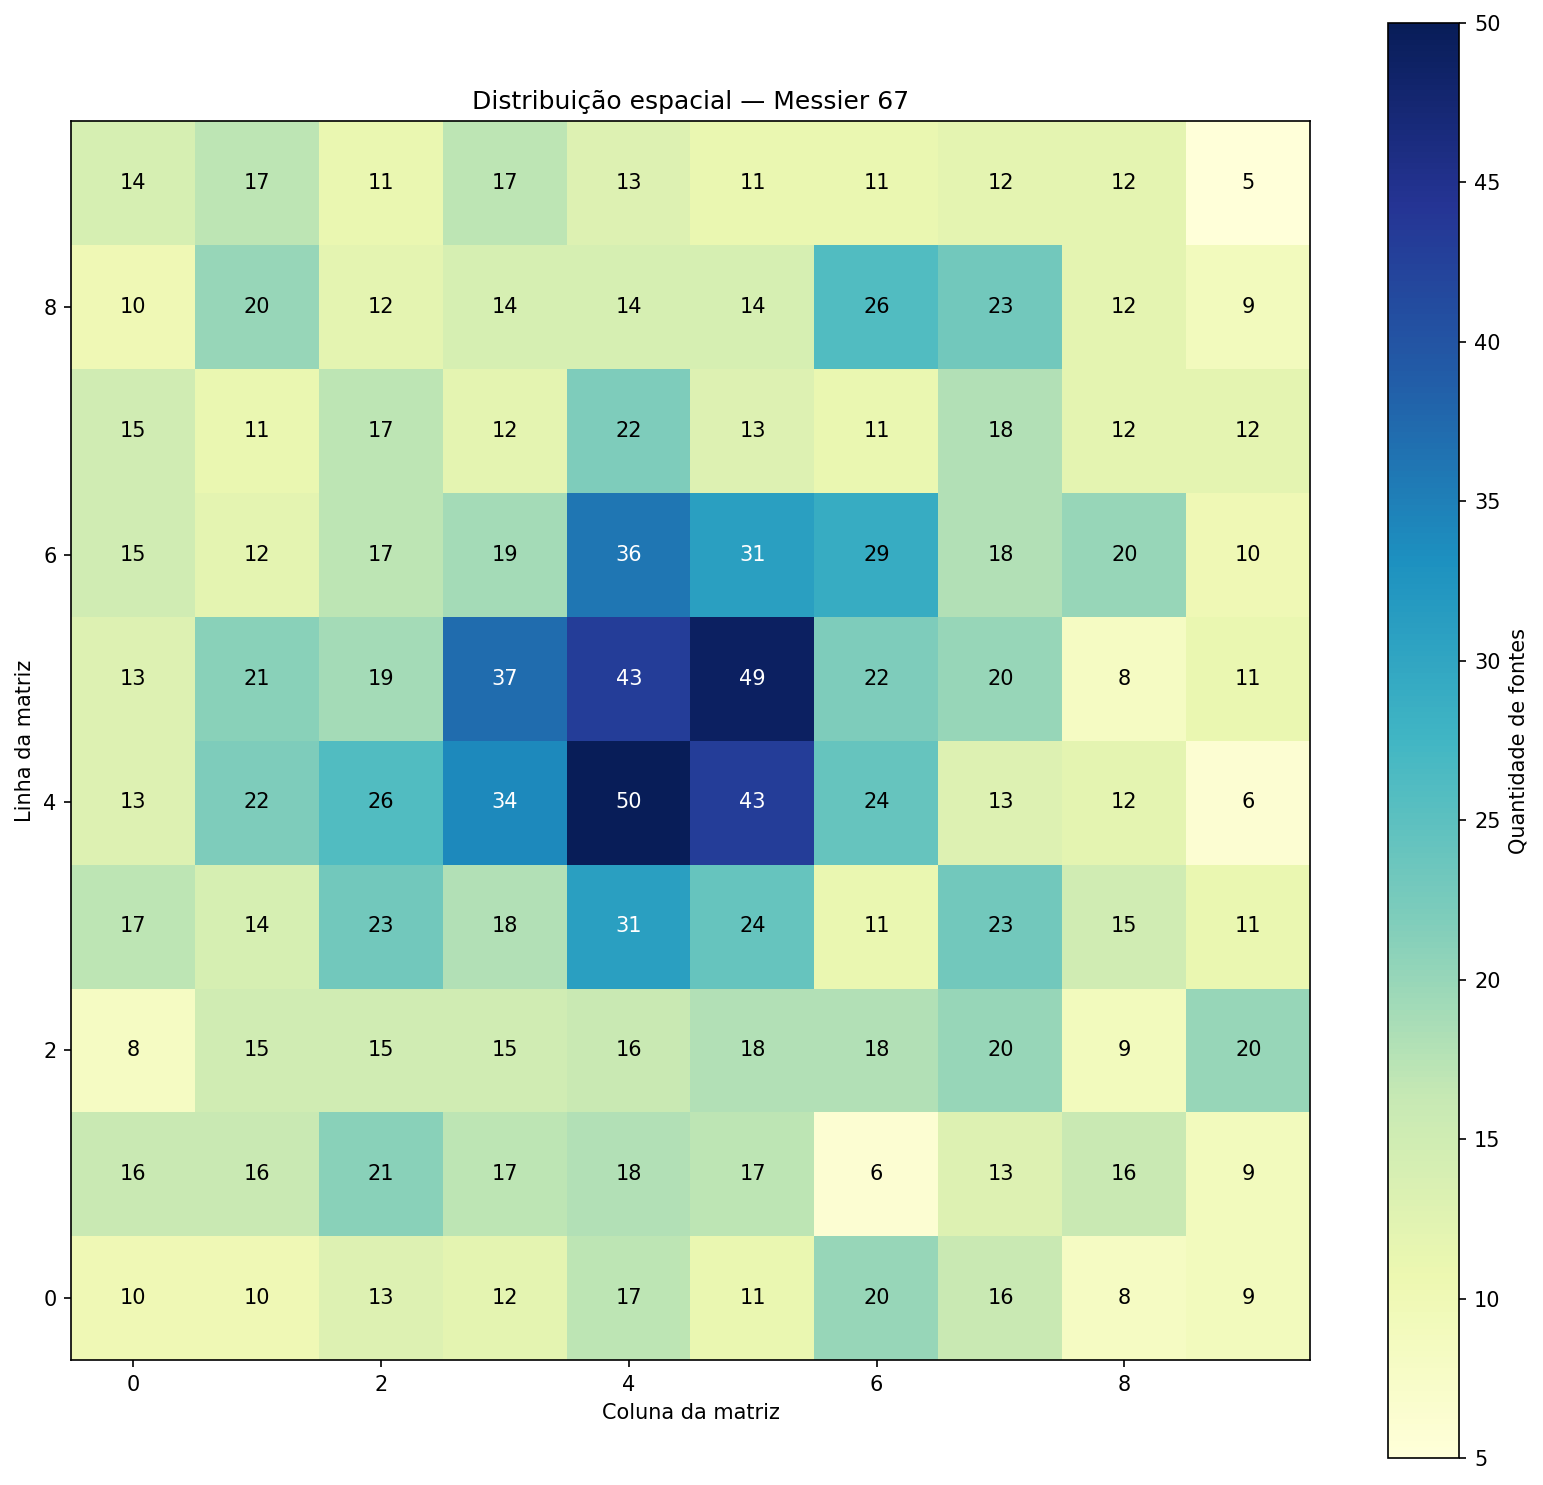

Total de fontes: 1729
Média por região: 17.29
Mediana: 15.0
Desvio padrão: 8.617766531996558
Maior concentração: 50.0
Menor concentração: 5.0


In [7]:
# Detecção com limiar de 7 sigma
detector = DAOStarFinder(
    fwhm=3.0,
    threshold=7 * desvio,
    min_separation=3.0,
    exclude_border=True
)

fontes7 = detector(imagem - mediana)

x = np.array(fontes7['x_centroid'])
y = np.array(fontes7['y_centroid'])

altura, largura = imagem.shape

# Divisão da imagem em 100 regiões
matriz, y_edges, x_edges = np.histogram2d(
    y, x,
    bins=(10, 10),
    range=[[-0.5, altura-0.5],
           [-0.5, largura-0.5]]
)

# Mapa de densidade
plt.figure(figsize=(11, 10), dpi=150)

plt.imshow(matriz, cmap='YlGnBu', origin='lower')

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, int(matriz[i, j]),
            ha='center', va='center',
            color='white' if matriz[i, j] >
            matriz.max()*0.6 else 'black'
        )

plt.colorbar(label='Quantidade de fontes')
plt.title('Distribuição espacial — Messier 67')
plt.xlabel('Coluna da matriz')
plt.ylabel('Linha da matriz')
plt.tight_layout()
plt.savefig('M67_densidade.png', dpi=300)
plt.show()

print('Total de fontes:', len(fontes7))
print('Média por região:', matriz.mean())
print('Mediana:', np.median(matriz))
print('Desvio padrão:', matriz.std())
print('Maior concentração:', matriz.max())
print('Menor concentração:', matriz.min())

pd.DataFrame(matriz.astype(int)).to_csv(
    'M67_matriz_densidade.csv', index=False
)

fontes7.write(
    'M67_fontes_7sigma.csv',
    format='csv', overwrite=True
)

In [8]:
from google.colab import files

files.download('M67_deteccao.png')
files.download('M67_sensibilidade.png')
files.download('M67_analise_ruido.png')
files.download('M67_densidade.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Distância média: 11.468022826164741
Mediana: 10.45532816543551
Desvio padrão: 8.046341031469396
Menor distância: 0.06514920830184212
Maior distância: 54.20550703717974


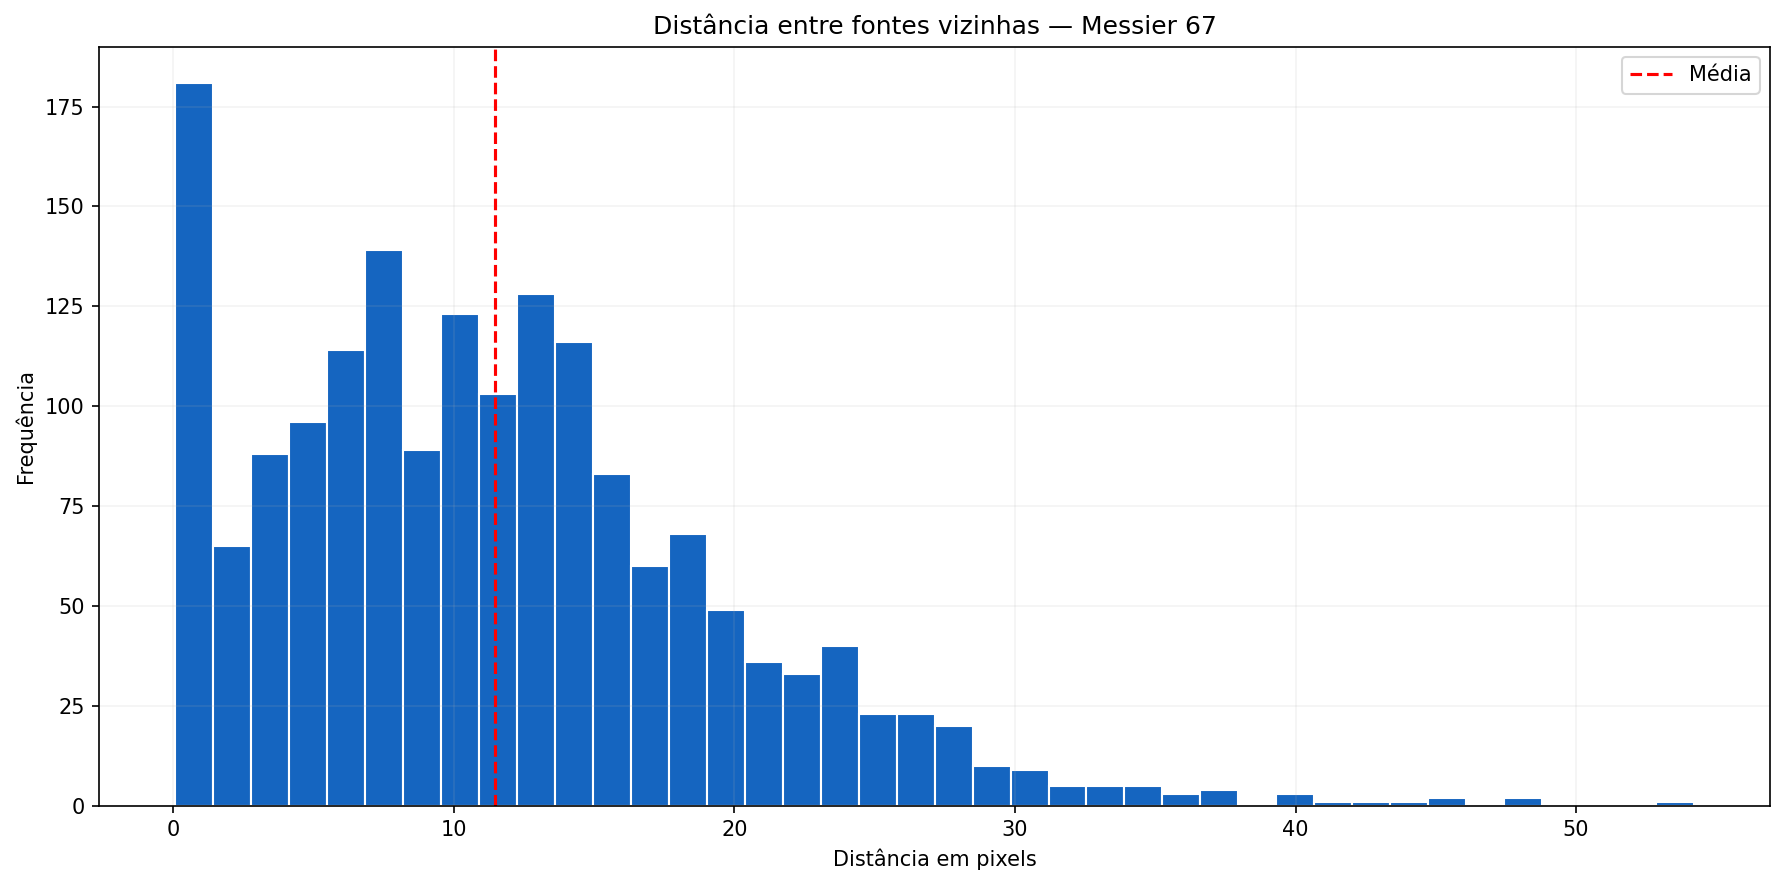

In [9]:
from scipy.spatial import cKDTree

coordenadas = np.column_stack((x, y))

arvore = cKDTree(coordenadas)

distancias, indices = arvore.query(
    coordenadas, k=2
)

distancia_minima = distancias[:, 1]

print('Distância média:', distancia_minima.mean())
print('Mediana:', np.median(distancia_minima))
print('Desvio padrão:', distancia_minima.std())
print('Menor distância:', distancia_minima.min())
print('Maior distância:', distancia_minima.max())

plt.figure(figsize=(12, 6), dpi=150)

plt.hist(
    distancia_minima,
    bins=40,
    color='#1565C0',
    edgecolor='white'
)

plt.axvline(
    distancia_minima.mean(),
    color='red',
    linestyle='--',
    label='Média'
)

plt.title('Distância entre fontes vizinhas — Messier 67')
plt.xlabel('Distância em pixels')
plt.ylabel('Frequência')
plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.savefig('M67_distancias.png', dpi=300)
plt.show()

pd.DataFrame({
    'X': x,
    'Y': y,
    'Distancia_vizinha': distancia_minima
}).to_csv('M67_distancias.csv', index=False)

Abaixo de 1 pixels:
Fontes: 167
Percentual: 9.66%

Abaixo de 2 pixels:
Fontes: 194
Percentual: 11.22%

Abaixo de 3 pixels:
Fontes: 254
Percentual: 14.69%

Abaixo de 5 pixels:
Fontes: 392
Percentual: 22.67%



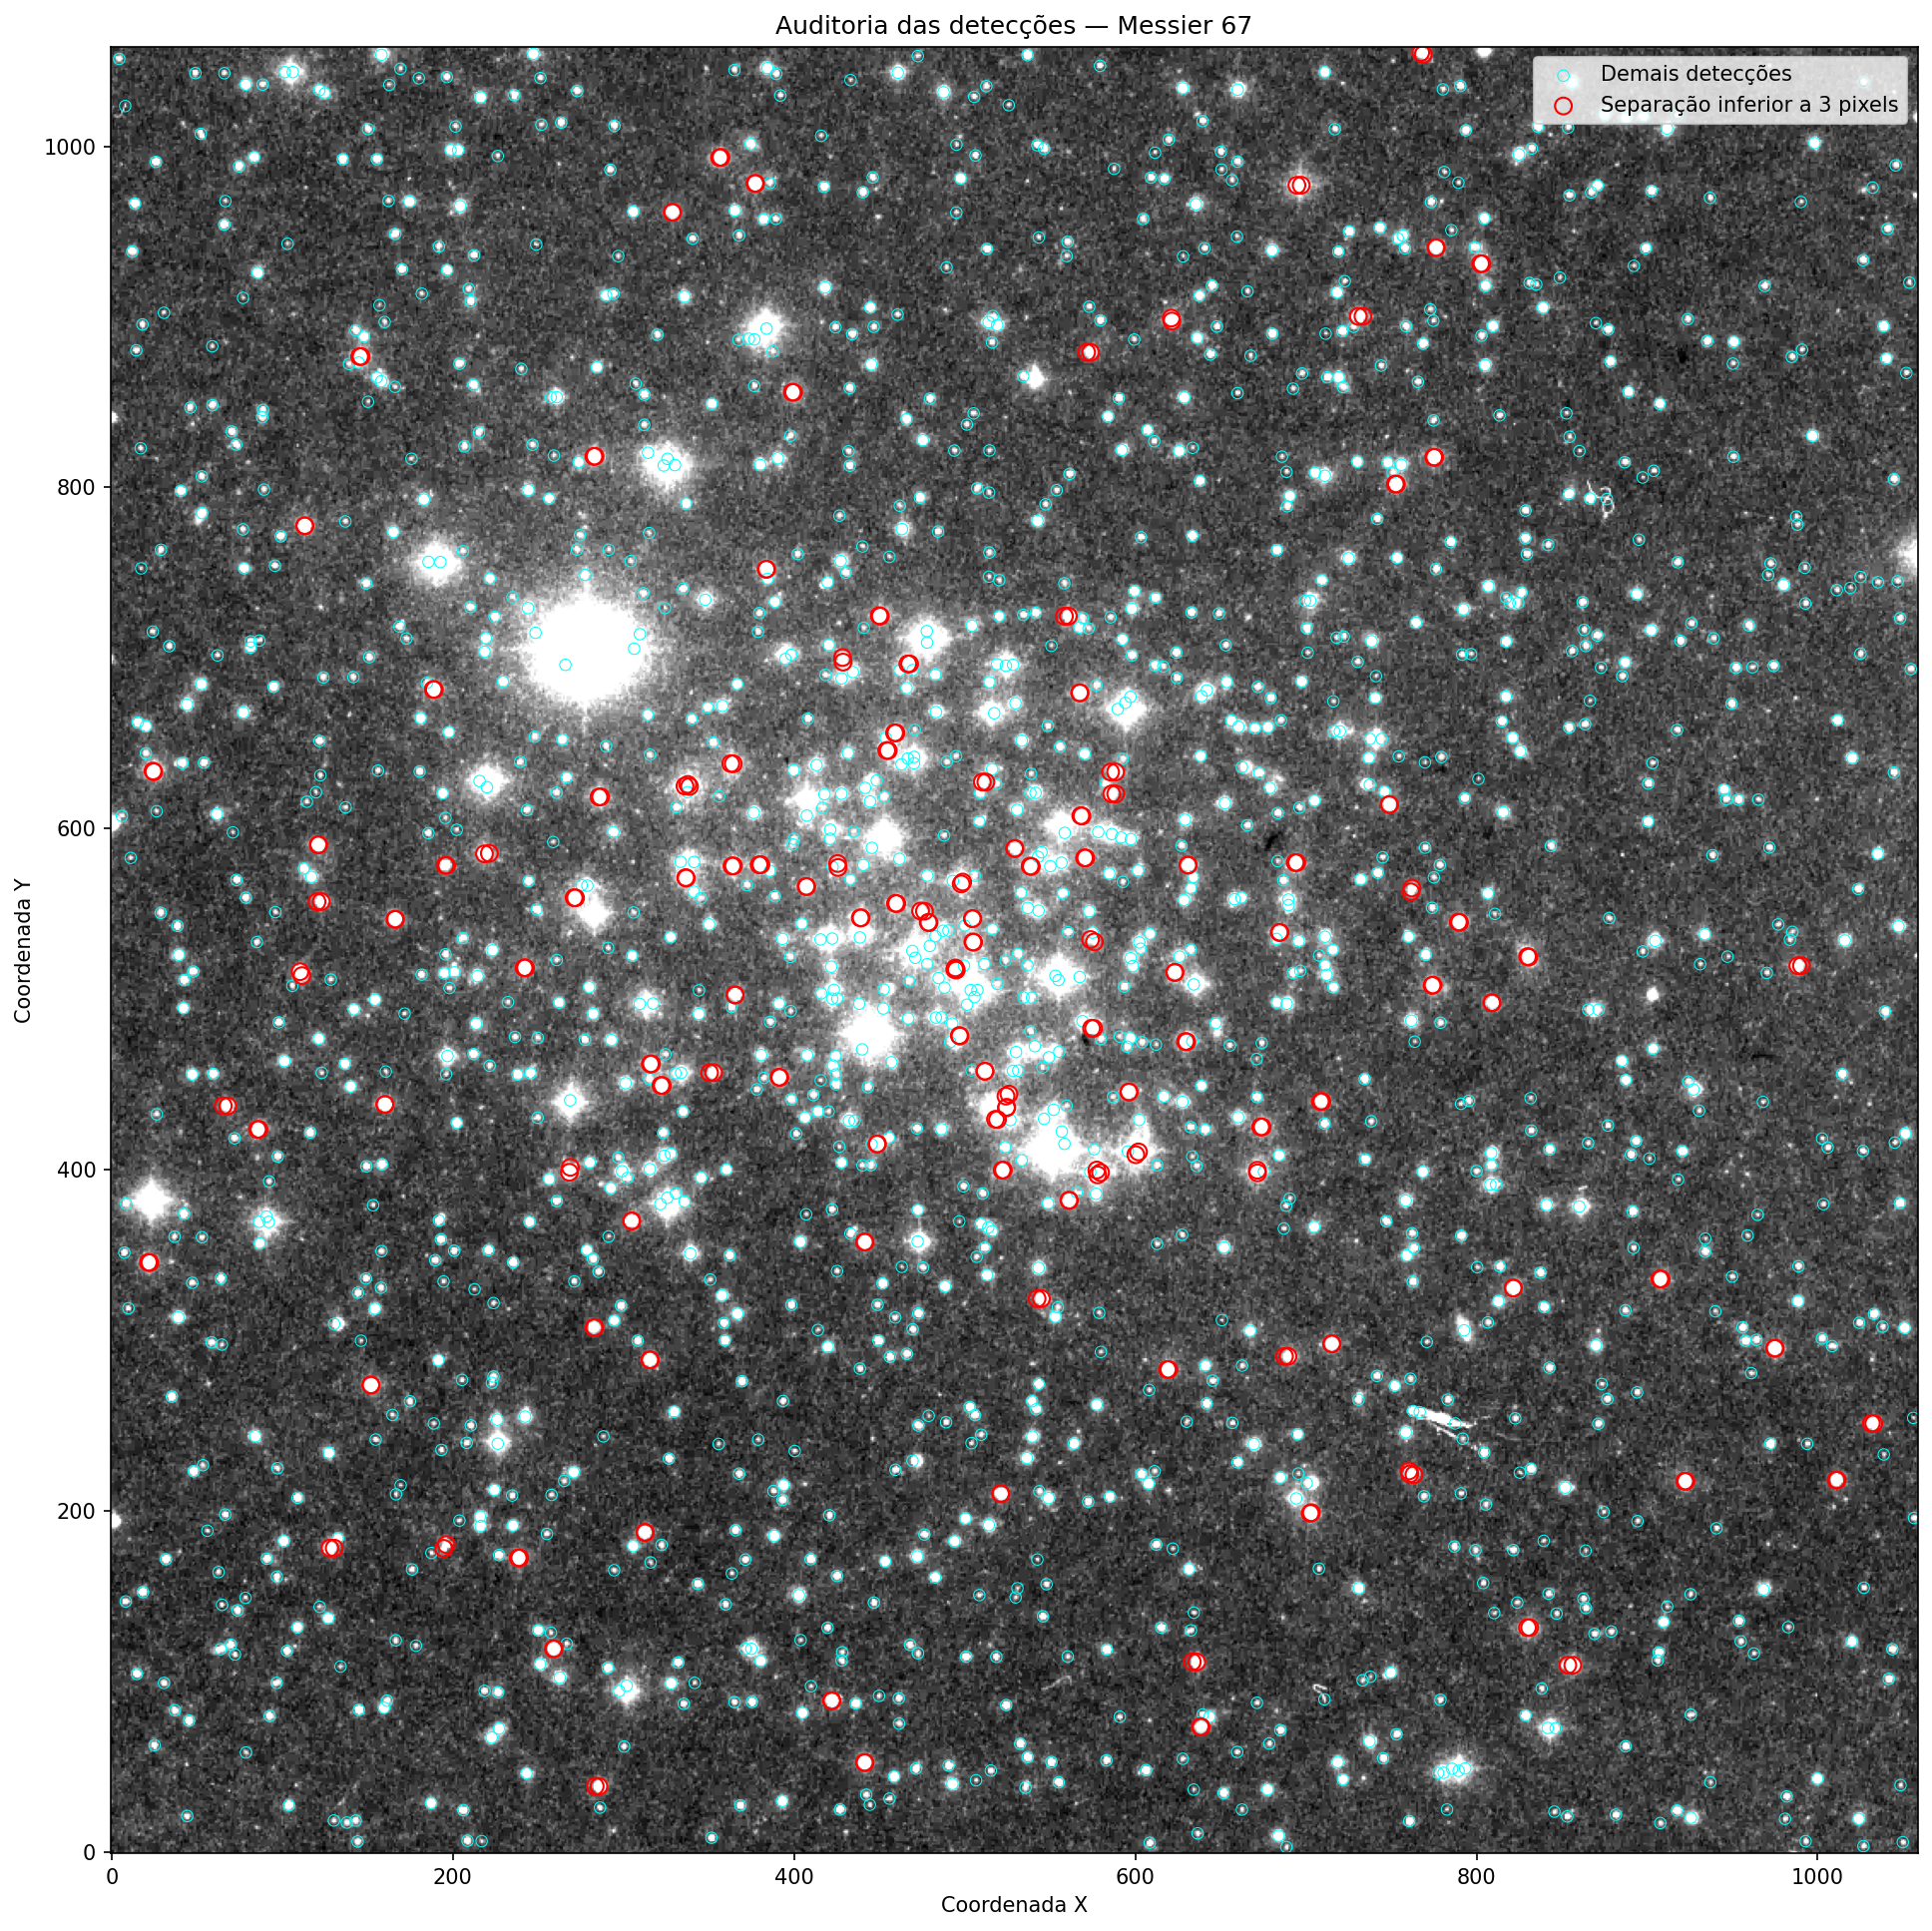

In [10]:
# Auditoria das distâncias

for limite in [1, 2, 3, 5]:
    quantidade = np.sum(distancia_minima < limite)
    percentual = 100 * quantidade / len(x)

    print(f'Abaixo de {limite} pixels:')
    print(f'Fontes: {quantidade}')
    print(f'Percentual: {percentual:.2f}%\n')

# Identificação de possíveis detecções múltiplas
suspeitas = distancia_minima < 3

plt.figure(figsize=(13, 13), dpi=150)

plt.imshow(
    imagem,
    cmap='gray',
    origin='lower',
    vmin=vmin,
    vmax=vmax
)

plt.scatter(
    x[~suspeitas], y[~suspeitas],
    s=30,
    facecolors='none',
    edgecolors='cyan',
    linewidths=0.5,
    label='Demais detecções'
)

plt.scatter(
    x[suspeitas], y[suspeitas],
    s=65,
    facecolors='none',
    edgecolors='red',
    linewidths=1,
    label='Separação inferior a 3 pixels'
)

plt.title('Auditoria das detecções — Messier 67')
plt.xlabel('Coordenada X')
plt.ylabel('Coordenada Y')
plt.legend()
plt.tight_layout()
plt.savefig('M67_auditoria.png', dpi=300)
plt.show()

In [11]:
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales

wcs = WCS(cabecalho)

print('METADADOS ASTRONÔMICOS\n')

for chave in [
    'OBJECT', 'TELESCOP', 'DATE-OBS',
    'EPOCH', 'EQUINOX', 'PLATEID',
    'CTYPE1', 'CTYPE2'
]:
    print(chave, ':', cabecalho.get(chave))

print('\nPossui coordenadas celestes:',
      wcs.has_celestial)

if wcs.has_celestial:

    escala = proj_plane_pixel_scales(
        wcs.celestial
    ) * 3600

    print('Escala angular:', escala,
          'segundos de arco por pixel')

    ceu = wcs.celestial.pixel_to_world(x, y)

    print('\nPrimeiras coordenadas celestes:')
    print(ceu.icrs[:10])

Changed DATE-OBS from '29/11/51' to '1951-11-29''. [astropy.wcs.wcs]
Changed DATE-OBS from '29/11/51' to '1951-11-29''.


METADADOS ASTRONÔMICOS

OBJECT : M67
TELESCOP : Palomar 48-inch Schmidt
DATE-OBS : 29/11/51
EPOCH : 1951.9110107422
EQUINOX : 2000.0
PLATEID : 07HH
CTYPE1 : None
CTYPE2 : None

Possui coordenadas celestes: True
Escala angular: [1.70037528 1.70078485] segundos de arco por pixel

Primeiras coordenadas celestes:
<SkyCoord (ICRS): (ra, dec) in deg
    [(132.7553674 , 11.56388412), (132.59231714, 11.5651067 ),
     (133.01777959, 11.56369352), (132.79396995, 11.56481717),
     (132.58119549, 11.5662721 ), (132.98672454, 11.56412029),
     (132.98274311, 11.56403328), (132.60866143, 11.56639888),
     (132.91781346, 11.56540853), (132.78045579, 11.56752819)]>


In [12]:
!pip -q install astroquery

In [13]:
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord
from astropy.time import Time
import astropy.units as u

# Centro e limites da imagem
centro = wcs.celestial.pixel_to_world(
    largura / 2, altura / 2
).icrs

cantos = wcs.celestial.pixel_to_world(
    [0, largura-1, 0, largura-1],
    [0, 0, altura-1, altura-1]
).icrs

raio = centro.separation(cantos).max().deg + 0.05

# Consulta ao catálogo Gaia DR3
consulta = f"""
SELECT source_id, ra, dec, pmra, pmdec,
       parallax, phot_g_mean_mag
FROM gaiadr3.gaia_source
WHERE 1 = CONTAINS(
    POINT('ICRS', ra, dec),
    CIRCLE('ICRS', {centro.ra.deg},
    {centro.dec.deg}, {raio})
)
"""

Gaia.ROW_LIMIT = -1

job = Gaia.launch_job_async(consulta)
gaia = job.get_results()

print('Fontes encontradas no Gaia:', len(gaia))

display(gaia[:10])

gaia.write(
    'M67_Gaia_DR3.ecsv',
    overwrite=True
)

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
Fontes encontradas no Gaia: 4448


source_id,ra,dec,pmra,pmdec,parallax,phot_g_mean_mag
,deg,deg,mas / yr,mas / yr,mas,mag
int64,float64,float64,float64,float64,float64,float32
598885051434474880,132.83957718669518,11.416874055653016,-0.8877131767371884,-10.712286653910212,-0.5994730593425588,19.91792
598885090090313216,132.81881130702303,11.412776236640019,-11.425226116157138,-2.5414879541695488,0.6223009458980135,19.20007
598885257595111296,132.84573169404388,11.4493714430574,2.005728280403797,-8.001040572583394,2.6221862273806362,20.85874
598885777284217856,132.7507740818141,11.434002654227989,--,--,--,21.100288
598886017802111104,132.83571089528093,11.462369707446507,-0.768868821759094,-1.2374660893704876,0.3012573450247268,12.906685
598886082226539136,132.81870312997395,11.459709259139215,-11.46615996623268,-3.465139511604465,1.20515733376285,17.289637
598889105883522688,132.71609165072886,11.482131153524714,0.2794141621712164,-3.6721765335978818,-0.3948045919359671,19.774277
598890617712105216,132.6865379638075,11.538318431261079,-11.33331419732188,-2.3785807432196595,1.402317824736573,20.526175


/usr/local/lib/python3.13/dist-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/usr/local/lib/python3.13/dist-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/usr/local/lib/python3.13/dist-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/usr/local/lib/python3.13/dist-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 3847 of "distance overridden (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/usr/local/lib/python3.13/dist-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)



Tolerância: 1 segundos de arco
Correspondências: 1399
Fontes Gaia distintas: 1342
Percentual: 80.91%

Tolerância: 2 segundos de arco
Correspondências: 1498
Fontes Gaia distintas: 1409
Percentual: 86.64%

Tolerância: 3 segundos de arco
Correspondências: 1521
Fontes Gaia distintas: 1427
Percentual: 87.97%

Tolerância: 5 segundos de arco
Correspondências: 1572
Fontes Gaia distintas: 1448
Percentual: 90.92%

Fontes Gaia com movimento próprio: 3847
Fontes Gaia excluídas por falta de movimento próprio: 601


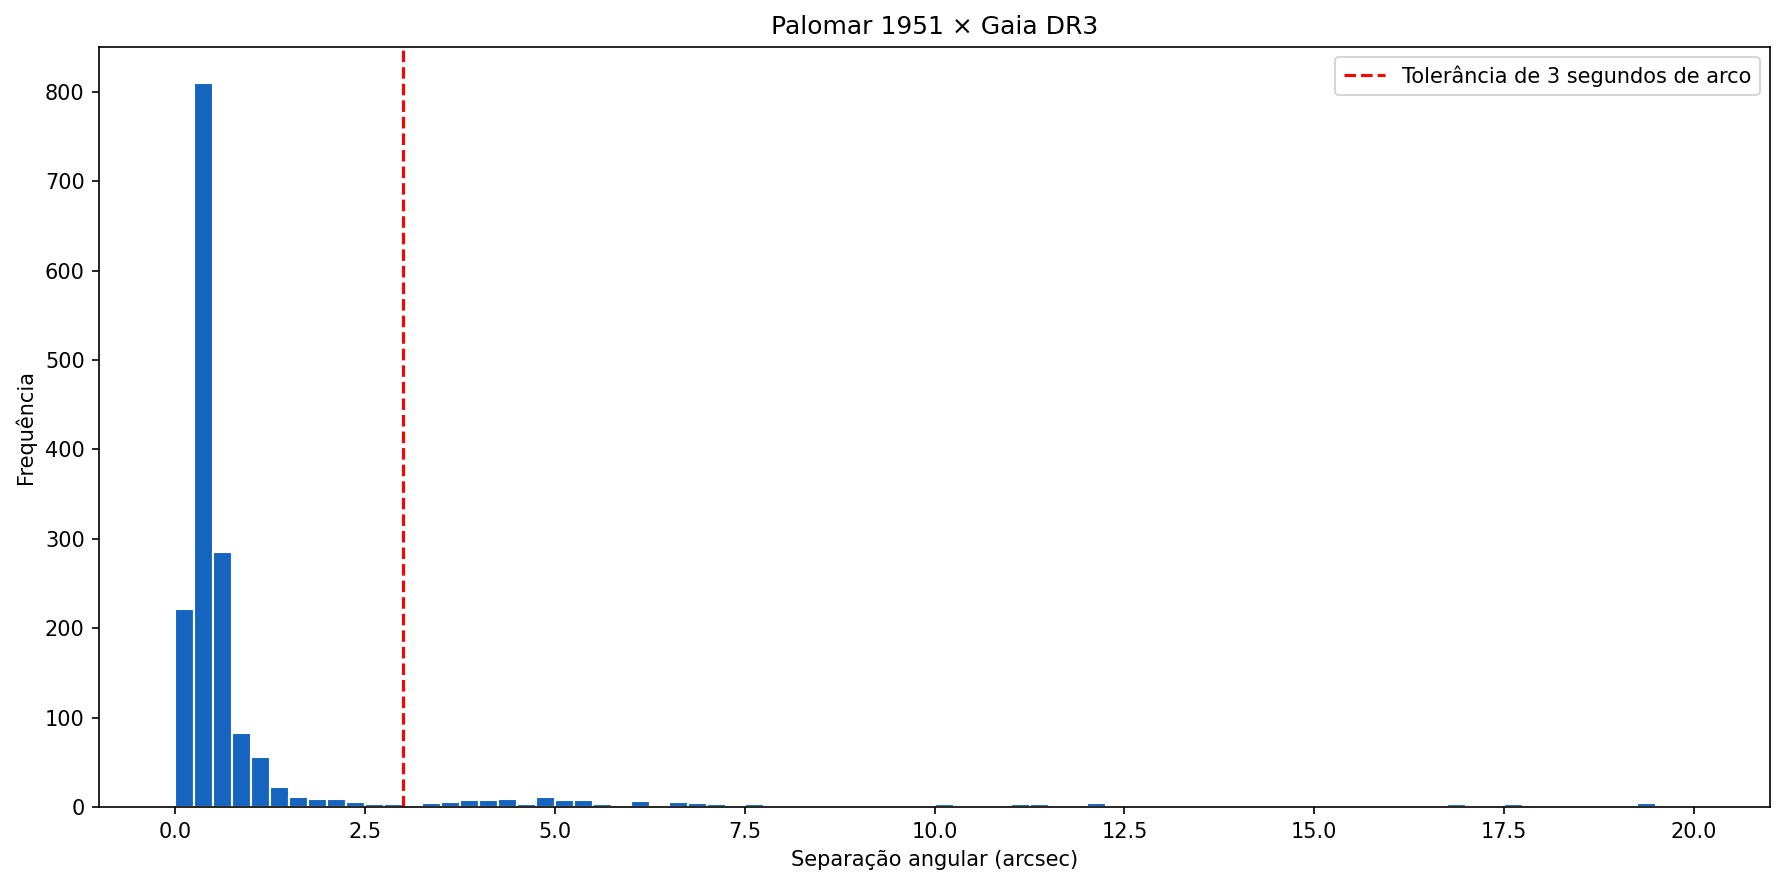

In [14]:
from astropy.coordinates import SkyCoord
from astropy.time import Time
import astropy.units as u

# Tratamento dos dados ausentes
def valores(coluna):
    return np.ma.asarray(
        gaia[coluna], dtype=float
    ).filled(np.nan)

pmra = valores('pmra')
pmdec = valores('pmdec')

validos = np.isfinite(pmra) & np.isfinite(pmdec)

catalogo = gaia[validos]

# Coordenadas na época de referência do Gaia
gaia2016 = SkyCoord(
    ra=valores('ra')[validos] * u.deg,
    dec=valores('dec')[validos] * u.deg,
    pm_ra_cosdec=pmra[validos] * u.mas/u.yr,
    pm_dec=pmdec[validos] * u.mas/u.yr,
    obstime=Time(2016.0, format='jyear')
)

# Estimar posições em 1951
gaia1951 = gaia2016.apply_space_motion(
    new_obstime=Time('1951-11-29')
)

# Cruzamento das coordenadas
idx, separacao, _ = ceu.icrs.match_to_catalog_sky(
    gaia1951
)

dist = separacao.arcsec

# Testar diferentes tolerâncias angulares
for limite in [1, 2, 3, 5]:

    mascara = dist <= limite
    quantidade = mascara.sum()
    unicas = len(np.unique(idx[mascara]))

    print(f'\nTolerância: {limite} segundos de arco')
    print(f'Correspondências: {quantidade}')
    print(f'Fontes Gaia distintas: {unicas}')
    print(f'Percentual: {100*quantidade/len(x):.2f}%')

print('\nFontes Gaia com movimento próprio:',
      len(catalogo))

print('Fontes Gaia excluídas por falta de movimento próprio:',
      len(gaia) - len(catalogo))

# Salvar resultados individuais
cruzamento = pd.DataFrame({
    'X': x,
    'Y': y,
    'RA': ceu.icrs.ra.deg,
    'DEC': ceu.icrs.dec.deg,
    'Gaia_ID': np.asarray(catalogo['source_id'])[idx],
    'Separacao_arcsec': dist,
    'Correspondencia_3arcsec': dist <= 3
})

cruzamento.to_csv(
    'M67_cruzamento_Gaia.csv',
    index=False
)

# Gráfico das separações
plt.figure(figsize=(12, 6), dpi=150)

plt.hist(
    dist,
    bins=np.linspace(0, 20, 81),
    color='#1565C0',
    edgecolor='white'
)

plt.axvline(
    3, color='red',
    linestyle='--',
    label='Tolerância de 3 segundos de arco'
)

plt.title('Palomar 1951 × Gaia DR3')
plt.xlabel('Separação angular (arcsec)')
plt.ylabel('Frequência')
plt.legend()
plt.tight_layout()
plt.savefig('M67_validacao_Gaia.png', dpi=300)
plt.show()

In [16]:
print('ESTATÍSTICA DAS SEPARAÇÕES ANGULARES')

for limite in [1, 2, 3, 5]:
    d = dist[dist <= limite]

    print(f'\nTolerância: {limite}"')
    print(f'Média: {np.mean(d):.4f}')
    print(f'Mediana: {np.median(d):.4f}')
    print(f'Desvio padrão: {np.std(d):.4f}')
    print(f'RMSE: {np.sqrt(np.mean(d**2)):.4f}')

print('\nDetecções além de 20":',
      np.sum(dist > 20))

ESTATÍSTICA DAS SEPARAÇÕES ANGULARES

Tolerância: 1"
Média: 0.4154
Mediana: 0.3916
Desvio padrão: 0.1813
RMSE: 0.4533

Tolerância: 2"
Média: 0.4731
Mediana: 0.4036
Desvio padrão: 0.2867
RMSE: 0.5532

Tolerância: 3"
Média: 0.5021
Mediana: 0.4072
Desvio padrão: 0.3699
RMSE: 0.6236

Tolerância: 5"
Média: 0.6210
Mediana: 0.4135
Desvio padrão: 0.7502
RMSE: 0.9739

Detecções além de 20": 49


,Deslocamento,Angulo,Correspondencias
0,30,0,40
1,30,45,33
2,30,90,45
3,30,135,35
4,30,180,39
5,30,225,38
6,30,270,49
7,30,315,34
8,60,0,40
9,60,45,34


Correspondências originais: 1521
Média ao acaso: 37.25
Desvio padrão: 6.3508529610858835


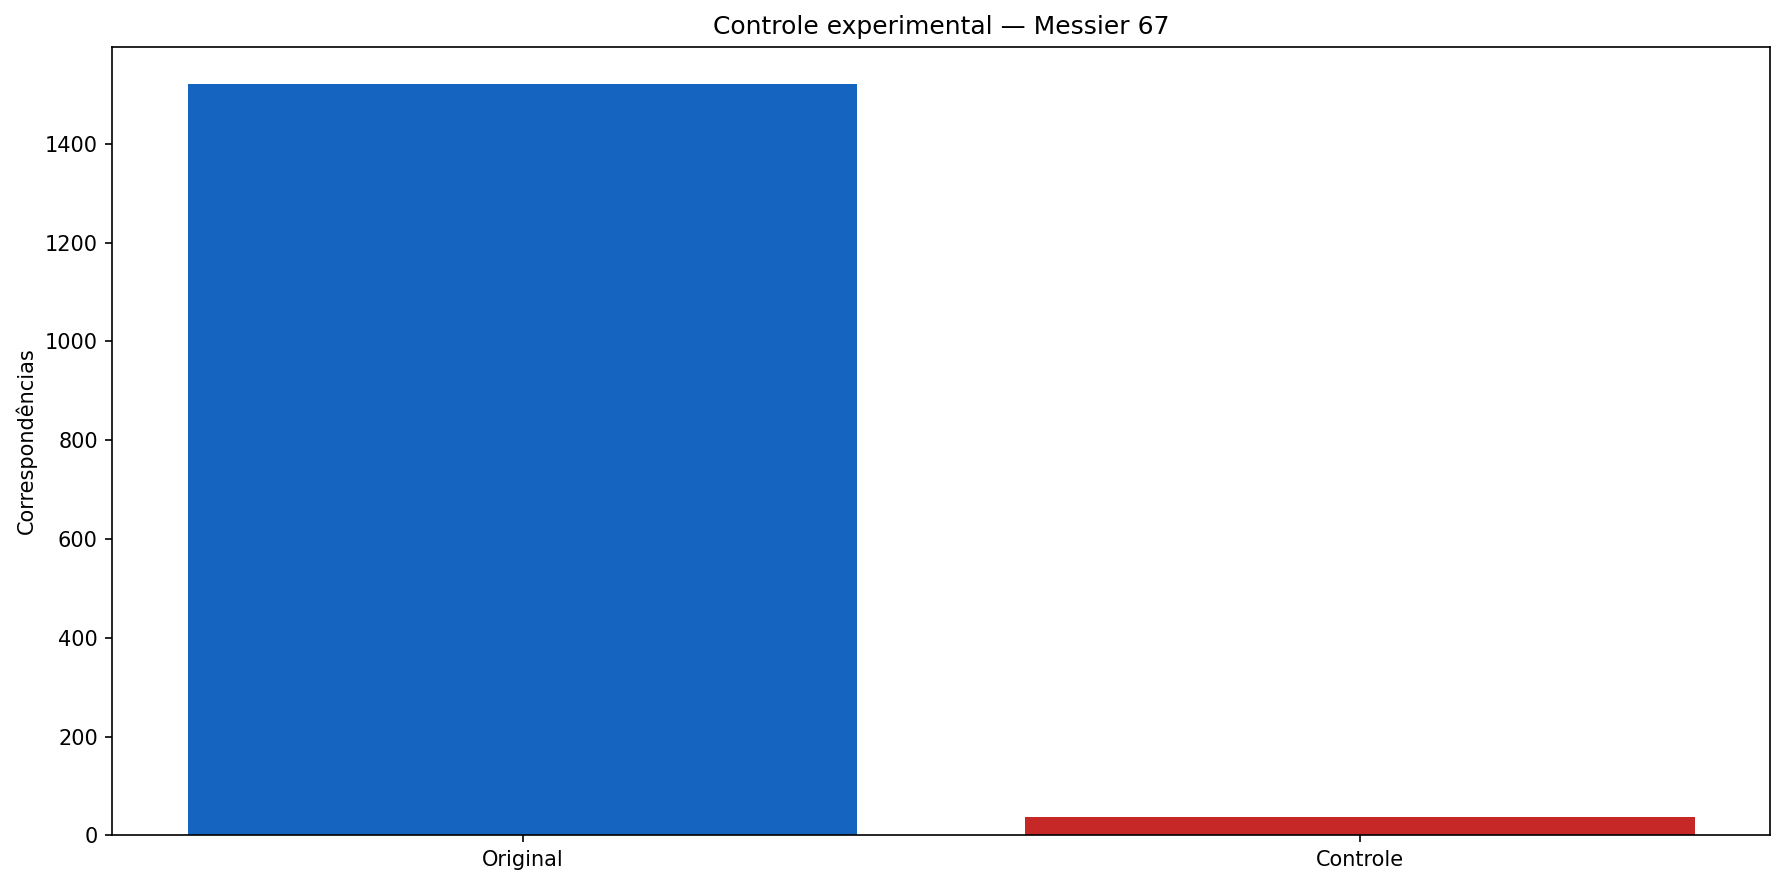

In [17]:
resultados_controle = []

for deslocamento in [30, 60]:
    for angulo in range(0, 360, 45):

        ceu_teste = ceu.icrs.directional_offset_by(
            angulo * u.deg,
            deslocamento * u.arcsec
        )

        _, sep, _ = ceu_teste.match_to_catalog_sky(
            gaia1951
        )

        resultados_controle.append({
            'Deslocamento': deslocamento,
            'Angulo': angulo,
            'Correspondencias': np.sum(sep.arcsec <= 3)
        })

teste = pd.DataFrame(resultados_controle)

display(teste)

media_acaso = teste['Correspondencias'].mean()

print('Correspondências originais:', np.sum(dist <= 3))
print('Média ao acaso:', media_acaso)
print('Desvio padrão:', teste['Correspondencias'].std())

plt.figure(figsize=(12, 6), dpi=150)

plt.bar(
    ['Original', 'Controle'],
    [np.sum(dist <= 3), media_acaso],
    color=['#1565C0', '#C62828']
)

plt.title('Controle experimental — Messier 67')
plt.ylabel('Correspondências')
plt.tight_layout()
plt.savefig('M67_controle.png', dpi=300)
plt.show()

teste.to_csv('M67_controle.csv', index=False)

,Tolerancia,Sem correcao,Com correcao
0,1,1240,1399
1,2,1461,1498
2,3,1499,1521
3,5,1565,1572


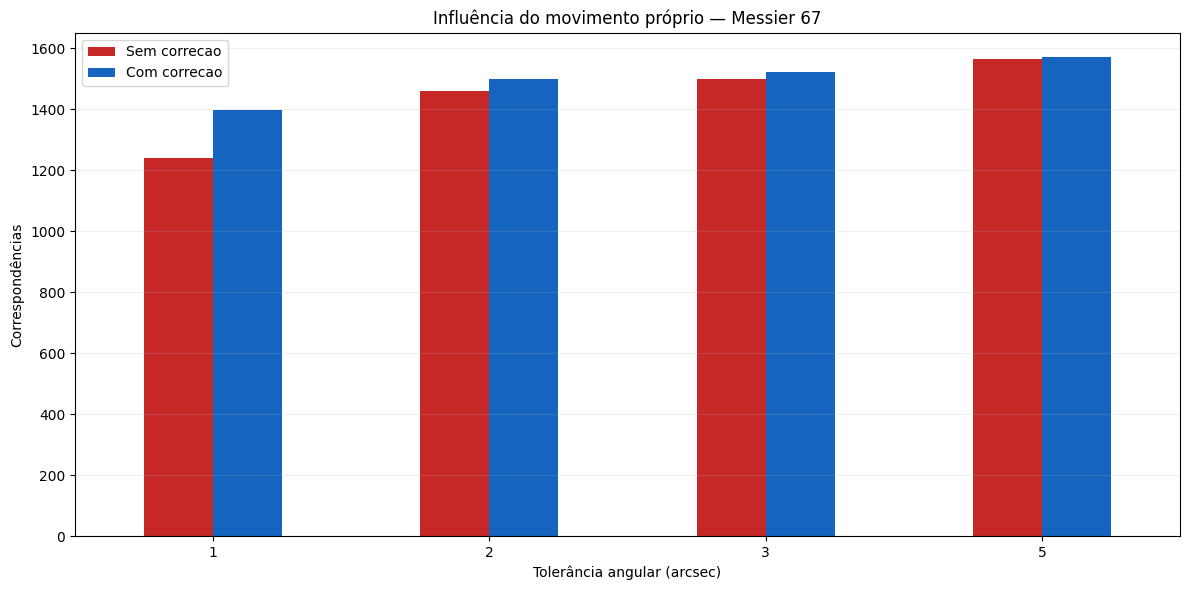

In [18]:
# Cruzamento sem correção do movimento próprio
idx2016, sep2016, _ = ceu.icrs.match_to_catalog_sky(
    gaia2016
)

# Comparação entre os dois métodos
resultados = []

for limite in [1, 2, 3, 5]:

    resultados.append({
        'Tolerancia': limite,
        'Sem correcao': np.sum(
            sep2016.arcsec <= limite
        ),
        'Com correcao': np.sum(
            dist <= limite
        )
    })

comparacao = pd.DataFrame(resultados)

display(comparacao)

comparacao.set_index('Tolerancia').plot(
    kind='bar',
    figsize=(12, 6),
    color=['#C62828', '#1565C0']
)

plt.title('Influência do movimento próprio — Messier 67')
plt.xlabel('Tolerância angular (arcsec)')
plt.ylabel('Correspondências')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig('M67_movimento_proprio.png', dpi=300)
plt.show()

comparacao.to_csv(
    'M67_movimento_proprio.csv',
    index=False
)

In [19]:
import glob
import zipfile
from google.colab import files

with zipfile.ZipFile(
    'Experimento_001_M67.zip', 'w',
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for nome in glob.glob('M67_*'):
        zipf.write(nome)

files.download('Experimento_001_M67.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>